# Benchmarks: OSCAR

*The compiled C++ of OSCAR, called from the R package, against the batched port on the CPU and on the GPU.*

OSCAR is the model of the participant-level run in [oscar/](oscar/README.md): a small network learning the inverse base-rate design trial by trial, one PSP search per participant. Its reference implementation is C++ with RcppArmadillo, called from R once per parameter set by `pspGlobal()`; the port, `psp.models.oscar`, runs a whole batch of parameter sets, and of participants, in one call. This notebook compares three builds:

- **R + C++**: psp 1.0.6 from CRAN, OSCAR compiled from [`benchmarks/oscar/tmp-models`](../benchmarks/oscar/tmp-models) with `Rcpp::sourceCpp()`, run with the routine's own `evaluate()` and `discretize()` (`convert.R`, `imac.R`), the participants spread over worker processes as `psp.R` does;
- **torch CPU float64** and **torch GPU float32**: `notebooks/oscar/run_oscar.py`, every participant's search advancing in lockstep with `PSPLockstep()`.

Two measurements: the cost of one call of the model, by the number of parameter sets it carries, and the whole routine for 14 participants. The scripts are in [`benchmarks/oscar`](../benchmarks/oscar) (`run.py` runs everything); this notebook only reads their results.

In [1]:
import os
import platform
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 4.6), "figure.dpi": 110, "savefig.dpi": 150,
    "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.spines.bottom": False, "axes.grid": True, "grid.color": "#e9ecef", "axes.axisbelow": True,
    "axes.labelcolor": "#495057", "xtick.color": "#495057", "ytick.color": "#495057",
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False, "legend.fontsize": 11,
})
grey, muted = "#6c757d", "#6c757d"
# the port's builds; R + C++ is the grey reference, drawn as dashed lines or grey bars
colours = {"cpu float64": "#eb6834", "cuda float32": "#2a78d6", "cuda float64": "#1baf7a"}


def titled(ax, title, subtitle=None, pad=0):
    ax.set_title(title, loc="left", pad=(26 if subtitle else 10) + pad)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 6 + pad),
                    textcoords="offset points", color=muted, fontsize=11, va="bottom")
    return ax


def us(v):
    return f"{v / 1000:,.2f} ms" if v >= 1000 else f"{v:,.1f} µs"


def times(v):
    return f"{v:,.0f}×" if v >= 10 else f"{v:.2g}×"


results = Path("../benchmarks/oscar/results")

## One call of the model

The first participant's 112 trials, with parameter sets drawn uniformly within the bounds of the routine. R calls the compiled `OSCAR()` once per parameter set, as `pspGlobal()` calls the model; the routine's `evaluate()` adds what happens around it in R: a fresh random initial state, and the data.table reduction to the mean P(rare) at test. The port's `evaluate()` does all of that for a whole batch in one call; its time includes `discretize()`.

In [2]:
r_model = pd.read_csv(results / "model_r.csv")
r_us = (1e6 * r_model.seconds / r_model.evaluations).groupby(r_model.what).median()
t_model = pd.read_csv(results / "model_torch.csv")
t_model["build"] = t_model.device + " " + t_model.dtype
per_call = t_model.groupby(["build", "batch"]).seconds.median().unstack("build")[list(colours)]
per_eval = 1e6 * per_call.div(per_call.index, axis=0)
pd.DataFrame({"per evaluation": r_us.map(us)}).rename_axis("R + RcppArmadillo, one call per parameter set")

,per evaluation
"R + RcppArmadillo, one call per parameter set",
OSCAR() alone,2.27 ms
evaluate(),5.36 ms


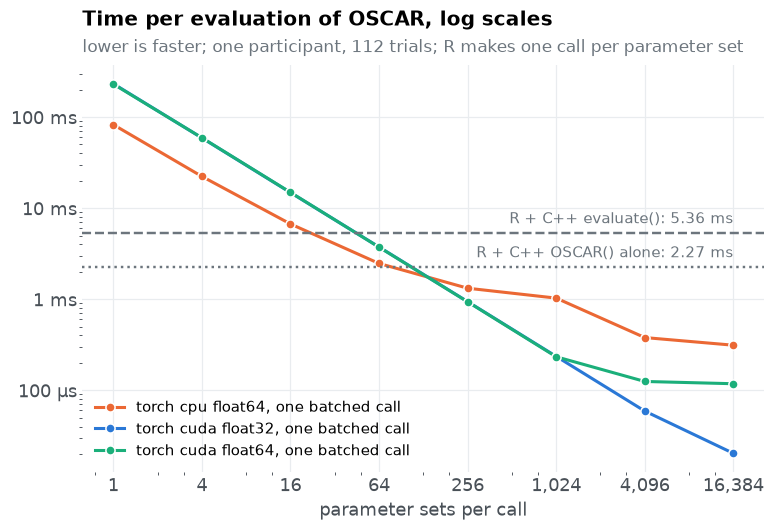

build,cpu float64,cuda float32,cuda float64,"vs R evaluate(), cpu float64","vs R evaluate(), cuda float32","vs R evaluate(), cuda float64"
parameter sets per call,,,,,,
1,82.57 ms,232.44 ms,230.44 ms,0.065×,0.023×,0.023×
4,22.30 ms,59.04 ms,59.24 ms,0.24×,0.091×,0.091×
16,6.70 ms,14.82 ms,14.89 ms,0.8×,0.36×,0.36×
64,2.47 ms,3.74 ms,3.73 ms,2.2×,1.4×,1.4×
256,1.32 ms,940.3 µs,936.6 µs,4.1×,5.7×,5.7×
1024,1.03 ms,235.6 µs,233.4 µs,5.2×,23×,23×
4096,379.3 µs,59.1 µs,125.0 µs,14×,91×,43×
16384,312.6 µs,20.3 µs,118.0 µs,17×,264×,45×


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for b, colour in colours.items():
    ax.plot(per_eval.index, per_eval[b], "-o", color=colour, linewidth=2, markersize=6,
            markeredgecolor="white", label=f"torch {b}, one batched call")
for what, style in [("evaluate()", "--"), ("OSCAR() alone", ":")]:
    ax.axhline(r_us[what], color=grey, linestyle=style, linewidth=1.6)
    ax.annotate(f"R + C++ {what}: {us(r_us[what])}", xy=(per_eval.index.max(), r_us[what]),
                xytext=(0, 4), textcoords="offset points", color=muted, fontsize=9.5, ha="right", va="bottom")
ax.set_xscale("log", base=4)
ax.set_yscale("log")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:g} ms" if v >= 1000 else f"{v:g} µs")
ax.set_xlabel("parameter sets per call")
ax.legend(loc="lower left", fontsize=9.5)
titled(ax, "Time per evaluation of OSCAR, log scales",
       "lower is faster; one participant, 112 trials; R makes one call per parameter set")
plt.show()
table = per_eval.map(us)
for b in colours:
    table[f"vs R evaluate(), {b}"] = (r_us["evaluate()"] / per_eval[b]).map(times)
table.rename_axis("parameter sets per call")

In [4]:
def crossover(b):
    faster = per_eval.index[per_eval[b] < r_us["evaluate()"]]
    return int(faster.min()) if len(faster) else None


single = per_call.loc[1]
gpu_flat = int(per_call.index[per_call["cuda float32"] < 1.1 * single["cuda float32"]].max())
largest = per_eval.index.max()
display(Markdown(f'''
A call of the port has a large fixed cost: {us(1e6 * single["cpu float64"])} on the CPU and {us(1e6 * single["cuda float32"])} on the GPU for a single parameter set, against {us(r_us["OSCAR() alone"])} for one call of the C++. On the GPU a call costs about the same up to {gpu_flat:,} parameter sets; on the CPU it grows, but far more slowly than the batch ({us(1e6 * per_call.loc[256, "cpu float64"])} for 256). OSCAR runs its 112 trials in order, and on every trial the port runs the ten recurrent attention shifts in order (for every row, keeping the result only where the trial learns), so one call is some 1,200 steps one after another, each a handful of tensor operations. Every operation costs a fixed amount of dispatch on the CPU and a kernel launch on the GPU, whether it works on one parameter set or on thousands. The C++ does the same steps without that overhead, which is why it wins for a single parameter set by a factor of {single["cpu float64"] / (r_us["OSCAR() alone"] / 1e6):.0f} on the CPU.

The batch pays that fixed cost once for every parameter set it carries. The port beats R's `evaluate()` from {crossover("cpu float64")} parameter sets per call on the CPU and from {crossover("cuda float32")} on the GPU, and at {largest:,} it is {times(r_us["evaluate()"] / per_eval.loc[largest, "cpu float64"])} faster on the CPU, {times(r_us["evaluate()"] / per_eval.loc[largest, "cuda float64"])} on the GPU in float64 and {times(r_us["evaluate()"] / per_eval.loc[largest, "cuda float32"])} in float32. Below a few thousand parameter sets the GPU's time is launches, not arithmetic, so float32 and float64 cost the same there (their lines coincide); above it, the card's slow double precision shows.
'''))


A call of the port has a large fixed cost: 82.57 ms on the CPU and 232.44 ms on the GPU for a single parameter set, against 2.27 ms for one call of the C++. On the GPU a call costs about the same up to 4,096 parameter sets; on the CPU it grows, but far more slowly than the batch (338.12 ms for 256). OSCAR runs its 112 trials in order, and on every trial the port runs the ten recurrent attention shifts in order (for every row, keeping the result only where the trial learns), so one call is some 1,200 steps one after another, each a handful of tensor operations. Every operation costs a fixed amount of dispatch on the CPU and a kernel launch on the GPU, whether it works on one parameter set or on thousands. The C++ does the same steps without that overhead, which is why it wins for a single parameter set by a factor of 36 on the CPU.

The batch pays that fixed cost once for every parameter set it carries. The port beats R's `evaluate()` from 64 parameter sets per call on the CPU and from 64 on the GPU, and at 16,384 it is 17× faster on the CPU, 45× on the GPU in float64 and 264× in float32. Below a few thousand parameter sets the GPU's time is launches, not arithmetic, so float32 and float64 cost the same there (their lines coincide); above it, the card's slow double precision shows.


## The participant-level routine

The routine of `psp.R` with reduced settings: the first 14 participants, 100 random starting points (one matrix shared by every participant, as `psp.R` draws it), radius 1, population 1,000,000 (so every pattern keeps proposing until the cap), 200 iterations, seed 2026.

- **R + C++** runs `pspGlobal()` once per participant, the participants spread over 14 forked worker processes: `psp.R` uses foreach over `detectCores() - 2` cores, which is 14 on this machine, so every worker runs one participant. Its time is the wall clock of the whole parallel run.
- **The port** runs `run_oscar.py --no-save` in one process: every participant's search advances in lockstep, and each iteration evaluates the proposals of all 14 participants in one batched call. Its time is the wall clock of that process, including Python's start-up, loading the data and initialising CUDA.

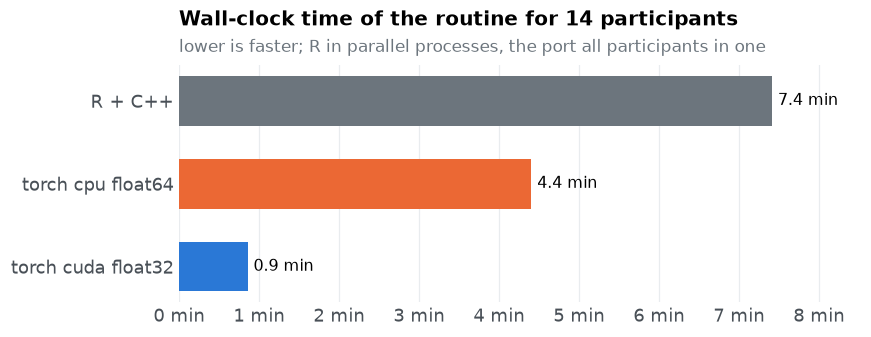

,"minutes, all participants",speed-up against R,evaluations per second,regions per participant,evaluations per participant
R + C++,7.4,1×,"1,111","198–216, median 204","35,417"
torch cpu float64,4.4,1.7×,"1,864","194–215, median 205","34,916"
torch cuda float32,0.9,8.6×,"9,706","196–220, median 208","35,461"


In [5]:
def keys_torch(directory):
    # every inequality matrix a run found, as the upper triangle in column-major order (as compare.R writes R's)
    rows = []
    for f in sorted((directory / "patterns").glob("OSCAR_4.*.npz")):
        z = np.load(f)
        for m, c in zip(z["ordinal_patterns"], z["ordinal_counts"], strict=True):
            rows.append({"ppt": f.stem.split(".", 1)[1], "count": int(c),
                         "key": ",".join(str(int(m[i, j])) for j in range(5) for i in range(j))})
    return pd.DataFrame(rows)


r_wall = pd.read_csv(results / "psp_r" / "wall.csv").iloc[0]
runs = {"R + C++": (float(r_wall.wall_seconds), pd.read_csv(results / "psp_r" / "summary.csv"),
                    pd.read_csv(results / "psp_r" / "patterns.csv"))}
for _, w in pd.read_csv(results / "psp_torch_wall.csv").iterrows():
    d = results / f"psp_torch_{w['device']}_{w['dtype']}"
    runs[f"torch {w['device']} {w['dtype']}"] = (float(w["wall_seconds"]), pd.read_csv(d / "tracking.csv"), keys_torch(d))
run_colours = {name: grey if name == "R + C++" else colours[name.removeprefix("torch ")] for name in runs}
n_ppt = int(r_wall.participants)
r_seconds = runs["R + C++"][0]

fig, ax = plt.subplots(figsize=(8, 2.8))
names = list(runs)[::-1]
minutes = [runs[n][0] / 60 for n in names]
ax.barh(names, minutes, color=[run_colours[n] for n in names], height=0.6)
for y, m in enumerate(minutes):
    ax.text(m + max(minutes) * 0.01, y, f"{m:.1f} min", va="center", fontsize=10.5)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(minutes) * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g} min")
titled(ax, f"Wall-clock time of the routine for {n_ppt} participants",
       "lower is faster; R in parallel processes, the port all participants in one")
plt.show()
pd.DataFrame({
    name: {
        "minutes, all participants": f"{seconds / 60:.1f}",
        "speed-up against R": times(r_seconds / seconds),
        "evaluations per second": f"{summary.evaluations.sum() / seconds:,.0f}",
        "regions per participant": f"{summary.patterns.min()}–{summary.patterns.max()}, median {summary.patterns.median():.0f}",
        "evaluations per participant": f"{summary.evaluations.median():,.0f}",
    }
    for name, (seconds, summary, _) in runs.items()
}).T

In [6]:
r_summary = runs["R + C++"][1]
lone = r_summary.evaluations.median() * r_us["evaluate()"] / 1e6
display(Markdown(f'''
Each R participant took a median of {r_summary.seconds.median():.0f} s in the parallel run. The same {r_summary.evaluations.median():,.0f} evaluations at the {us(r_us["evaluate()"])} of a lone `evaluate()` would take {lone:.0f} s, so with {int(r_wall.workers)} workers on {os.cpu_count()} hardware threads ({os.cpu_count() // 2} cores) each R process ran {r_summary.seconds.median() / lone:.1f} times slower than alone: the workers compete for the cores. That is the routine as `psp.R` runs it on this machine. The port's CPU run is one process using torch's own threads ({torch.get_num_threads()} here) inside each operation.
'''))


Each R participant took a median of 419 s in the parallel run. The same 35,417 evaluations at the 5.36 ms of a lone `evaluate()` would take 190 s, so with 14 workers on 16 hardware threads (8 cores) each R process ran 2.2 times slower than alone: the workers compete for the cores. That is the routine as `psp.R` runs it on this machine. The port's CPU run is one process using torch's own threads (8 here) inside each operation.


### How large are the batches of a real run?

The single-call measurements above predict the routine only if we know how many parameter sets a call of the routine carries. In a PSP run that is the number of patterns still filling, summed over the participants: iteration 0 evaluates every starting point of every participant, and every later iteration one proposal per pattern found so far. With a population of a million, no pattern ever fills, so every pattern proposes on every iteration.

In [7]:
seconds, tracking, _ = runs["torch cuda float32"]
iterations = int(tracking.iterations.max())
per_iteration = tracking.evaluations.sum() / iterations
start = 100 * n_ppt
final = tracking.patterns.sum()


def model_us(b, batch):
    # time per evaluation of one call at `batch` parameter sets, interpolated on the log-log curve above
    return float(np.exp(np.interp(np.log(batch), np.log(per_eval.index), np.log(per_eval[b]))))


def routine_us(name):
    seconds, summary, _ = runs[name]
    return 1e6 * seconds / summary.evaluations.sum()


display(Markdown(f'''
Iteration 0 evaluates {start:,} parameter sets ({n_ppt} participants × 100 starting points); by the last iteration the participants hold {final:,} patterns between them, so the last call carries {final:,}, and on average a call carried {per_iteration:,.0f}. At that batch size the curve above puts one evaluation of the model alone at about {us(model_us("cpu float64", per_iteration))} on the CPU and {us(model_us("cuda float32", per_iteration))} on the GPU in float32. The whole routine, divided by the evaluations it made, cost {us(routine_us("torch cpu float64"))} and {us(routine_us("torch cuda float32"))} per evaluation: almost all of a run is the model, and proposing, discretizing and the pattern stores add little.

R's single-process cost is {us(r_us["evaluate()"])} per evaluation, but its {int(r_wall.workers)} processes together made one evaluation every {us(routine_us("R + C++"))}: running the participants in parallel bought {r_us["evaluate()"] / routine_us("R + C++"):.1f}× on {os.cpu_count() // 2} cores. Against that parallel R, the port's batched call is what remains of its advantage: {times(r_seconds / runs["torch cpu float64"][0])} on the CPU in one process, and {times(r_seconds / seconds)} on the GPU.

The batch grows with the number of participants run together. {n_ppt} participants with about 200 patterns each give a few thousand parameter sets per call; all 354 participants of the dataset would give some 70,000, where the GPU's lead per evaluation is largest, while R's processes would still share the same {os.cpu_count() // 2} cores.
'''))


Iteration 0 evaluates 1,400 parameter sets (14 participants × 100 starting points); by the last iteration the participants hold 2,903 patterns between them, so the last call carries 2,903, and on average a call carried 2,498. At that batch size the curve above puts one evaluation of the model alone at about 541.4 µs on the CPU and 96.8 µs on the GPU in float32. The whole routine, divided by the evaluations it made, cost 536.4 µs and 103.0 µs per evaluation: almost all of a run is the model, and proposing, discretizing and the pattern stores add little.

R's single-process cost is 5.36 ms per evaluation, but its 14 processes together made one evaluation every 900.1 µs: running the participants in parallel bought 6.0× on 8 cores. Against that parallel R, the port's batched call is what remains of its advantage: 1.7× on the CPU in one process, and 8.6× on the GPU.

The batch grows with the number of participants run together. 14 participants with about 200 patterns each give a few thousand parameter sets per call; all 354 participants of the dataset would give some 70,000, where the GPU's lead per evaluation is largest, while R's processes would still share the same 8 cores.


### Do the builds find the same regions?

The model draws its initial state at random on every evaluation, and R and torch use different random numbers, so no two runs take the same path. Per participant, the inequality matrices each port build shares with R:

In [8]:
r_keys = runs["R + C++"][2]
rows = []
for name, (_, _, keys) in list(runs.items())[1:]:
    for ppt, mine in keys.groupby("ppt"):
        theirs = r_keys[r_keys.ppt == ppt]
        shared = set(mine.key) & set(theirs.key)
        rows.append({
            "build": name, "ppt": ppt, "shared": len(shared),
            "R only": len(set(theirs.key) - shared), "torch only": len(set(mine.key) - shared),
            "R": theirs[theirs.key.isin(shared)]["count"].sum() / theirs["count"].sum(),
            "torch": mine[mine.key.isin(shared)]["count"].sum() / mine["count"].sum(),
        })
overlap = pd.DataFrame(rows)
summary = overlap.groupby("build").agg(
    shared=("shared", "median"), r_only=("R only", "median"), torch_only=("torch only", "median"),
    r_worst=("R", "min"), torch_worst=("torch", "min"))
pd.DataFrame({
    "matrices shared with R, median": summary.shared.map("{:.0f}".format),
    "found by R only, median": summary.r_only.map("{:.0f}".format),
    "found by the port only, median": summary.torch_only.map("{:.0f}".format),
    "evaluations in shared matrices, worst participant": [f"R {r.r_worst:.1%}, port {r.torch_worst:.1%}" for _, r in summary.iterrows()],
})

,"matrices shared with R, median","found by R only, median","found by the port only, median","evaluations in shared matrices, worst participant"
build,,,,
torch cpu float64,196,8,6,"R 99.7%, port 99.9%"
torch cuda float32,198,6,9,"R 99.9%, port 99.7%"


The matrices only one build found are the rare ones, holding one or a few evaluations each: practically every evaluation of either run falls in a matrix both found. The port finds the same partition as the C++, at a fraction of the time. That the two implementations compute the same model is checked separately, to 1e-10 on the trial-by-trial output, by `tests/test_oscar.py` and [oscar/try_oscar.py](oscar/try_oscar.py).

## How this was measured

In [9]:
def r_version():
    try:
        return subprocess.run(["Rscript", "-e", "cat(R.version.string)"], capture_output=True, text=True,
                              timeout=60).stdout.strip() or "not found"
    except OSError:
        return "not found"


def cpu_name():
    try:
        return next(line.split(":", 1)[1].strip() for line in open("/proc/cpuinfo") if line.startswith("model name"))
    except (OSError, StopIteration):
        return platform.processor() or "unknown"


pd.DataFrame({"": {
    "CPU": f"{cpu_name()}, {os.cpu_count()} threads",
    "GPU": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none",
    "System": f"{platform.system()} {platform.release()}",
    "torch": f"{torch.__version__}, {torch.get_num_threads()} threads",
    "Python": platform.python_version(),
    "R": r_version(),
    "R package": "psp 1.0.6 (CRAN), OSCAR compiled with Rcpp::sourceCpp() at R's default -O2",
}}).rename_axis("Environment")

,
Environment,
CPU,"AMD Ryzen 7 5800X 8-Core Processor, 16 threads"
GPU,NVIDIA GeForce RTX 3060
System,Linux 7.0.0-38-generic
torch,"2.11.0+cu128, 8 threads"
Python,3.14.4
R,R version 4.5.2 (2025-10-31)
R package,"psp 1.0.6 (CRAN), OSCAR compiled with Rcpp::so..."


The results are from this machine, measured with nothing else running. To measure them again (about 15 minutes), install the R package into its own library, run the benchmark and re-execute this notebook:

```sh
Rscript -e 'install.packages("psp", lib = "benchmarks/oscar/r-lib", repos = "https://cloud.r-project.org")'
uv run python benchmarks/oscar/run.py --r-library benchmarks/oscar/r-lib
uv run python notebooks/execute.py benchmarks-oscar.ipynb
```

`--participants`, `--starts`, `--iterations` and `--workers` change the routine's settings; [benchmarks/oscar/README.md](../benchmarks/oscar/README.md) describes every script.